In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving songs_normalize.csv to songs_normalize.csv


In [3]:
import io

filename = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("File:", filename)

Dataset loaded successfully!
File: songs_normalize.csv


In [4]:
df.head()

,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop


In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (2000, 18)


In [6]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['artist', 'song', 'duration_ms', 'explicit', 'year', 'popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'genre']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   artist            2000 non-null   object 
 1   song              2000 non-null   object 
 2   duration_ms       2000 non-null   int64  
 3   explicit          2000 non-null   bool   
 4   year              2000 non-null   int64  
 5   popularity        2000 non-null   int64  
 6   danceability      2000 non-null   float64
 7   energy            2000 non-null   float64
 8   key               2000 non-null   int64  
 9   loudness          2000 non-null   float64
 10  mode              2000 non-null   int64  
 11  speechiness       2000 non-null   float64
 12  acousticness      2000 non-null   float64
 13  instrumentalness  2000 non-null   float64
 14  liveness          2000 non-null   float64
 15  valence           2000 non-null   float64
 16  tempo             2000 non-null   float64


In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
artist              0
song                0
duration_ms         0
explicit            0
year                0
popularity          0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
genre               0
dtype: int64


In [9]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 59


In [10]:
print(df["popularity"].describe())

count    2000.000000
mean       59.872500
std        21.335577
min         0.000000
25%        56.000000
50%        65.500000
75%        73.000000
max        89.000000
Name: popularity, dtype: float64


In [11]:
print("Minimum Popularity:", df["popularity"].min())
print("Maximum Popularity:", df["popularity"].max())

Minimum Popularity: 0
Maximum Popularity: 89


In [12]:

print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate rows after cleaning:", df.duplicated().sum())
print("New dataset shape:", df.shape)

Duplicate rows before cleaning: 59
Duplicate rows after cleaning: 0
New dataset shape: (1941, 18)


In [13]:


def popularity_category(score):
    if score >= 70:
        return "Popular"
    elif score >= 40:
        return "Moderately Popular"
    else:
        return "Not Popular"

df["popularity_category"] = df["popularity"].apply(popularity_category)

print("Popularity categories created successfully!")

Popularity categories created successfully!


In [14]:
print(df[["popularity", "popularity_category"]].head(20))

    popularity popularity_category
0           77             Popular
1           79             Popular
2           66  Moderately Popular
3           78             Popular
4           65  Moderately Popular
5           69  Moderately Popular
6           86             Popular
7           68  Moderately Popular
8           75             Popular
9           77             Popular
10           1         Not Popular
11          56  Moderately Popular
12          55  Moderately Popular
13          62  Moderately Popular
14          61  Moderately Popular
15          53  Moderately Popular
16          64  Moderately Popular
17          73             Popular
18          64  Moderately Popular
19          82             Popular


In [15]:
category_counts = df["popularity_category"].value_counts()

print("Number of songs in each category:")
print(category_counts)

Number of songs in each category:
popularity_category
Moderately Popular    1026
Popular                699
Not Popular            216
Name: count, dtype: int64


In [16]:
category_percentage = (
    df["popularity_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Percentage of songs in each category:")
print(category_percentage)

Percentage of songs in each category:
popularity_category
Moderately Popular    52.86
Popular               36.01
Not Popular           11.13
Name: proportion, dtype: float64


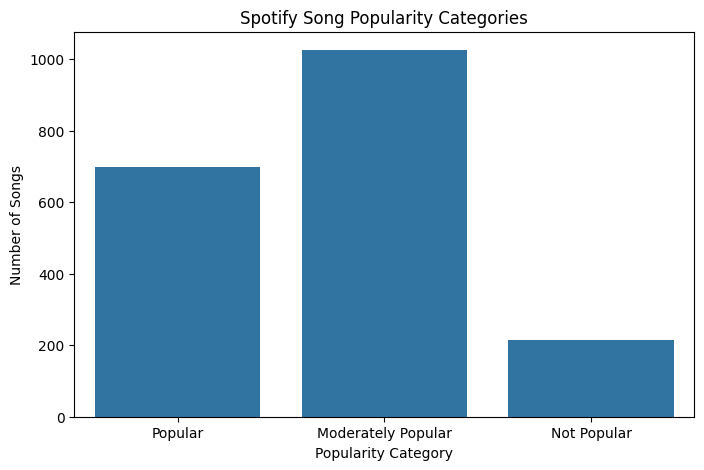

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="popularity_category"
)

plt.title("Spotify Song Popularity Categories")
plt.xlabel("Popularity Category")
plt.ylabel("Number of Songs")

plt.show()

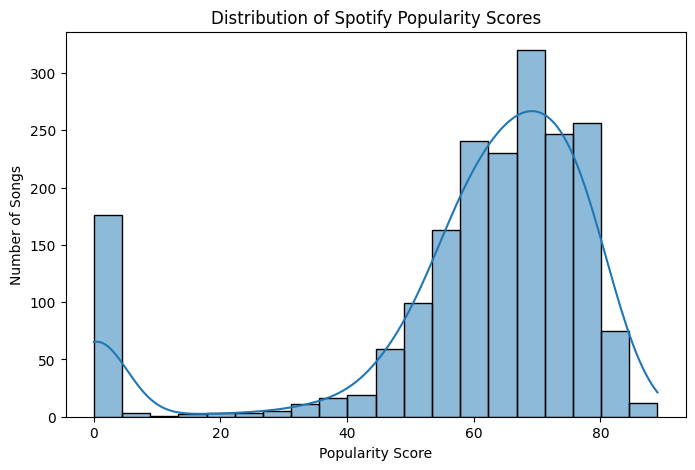

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="popularity",
    bins=20,
    kde=True
)

plt.title("Distribution of Spotify Popularity Scores")
plt.xlabel("Popularity Score")
plt.ylabel("Number of Songs")

plt.show()

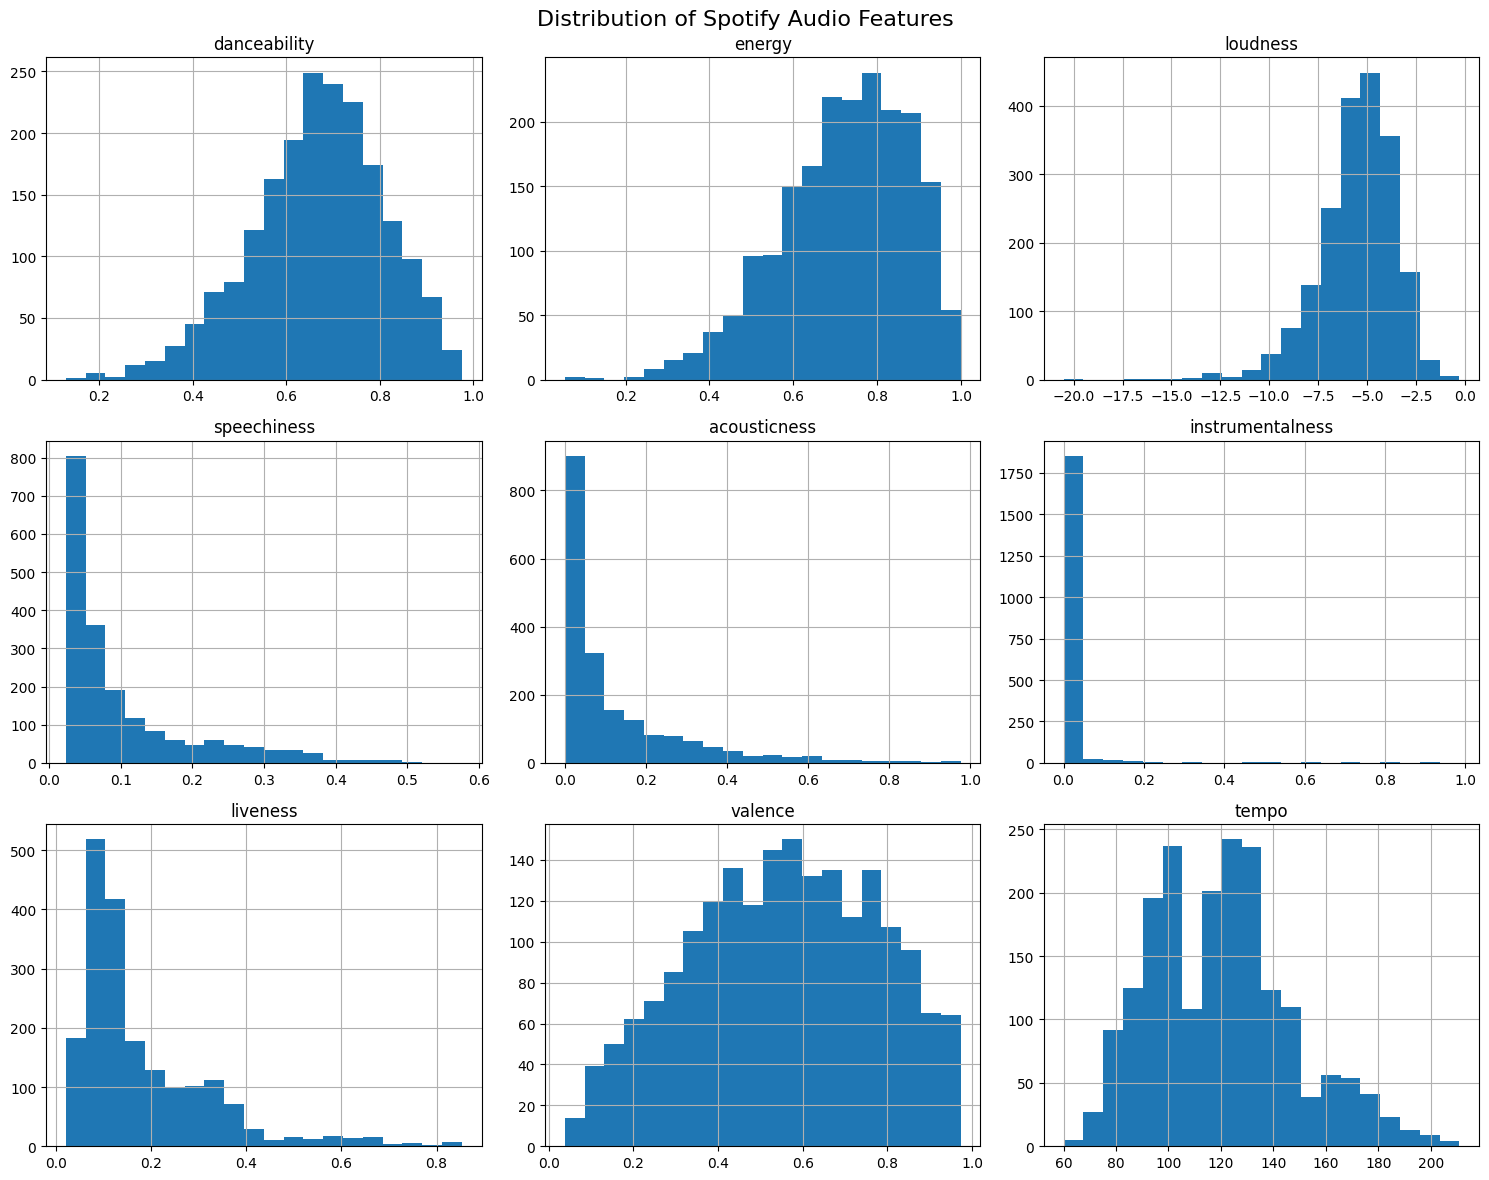

In [19]:
features_to_plot = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

df[features_to_plot].hist(
    figsize=(15, 12),
    bins=20
)

plt.suptitle("Distribution of Spotify Audio Features", fontsize=16)
plt.tight_layout()
plt.show()

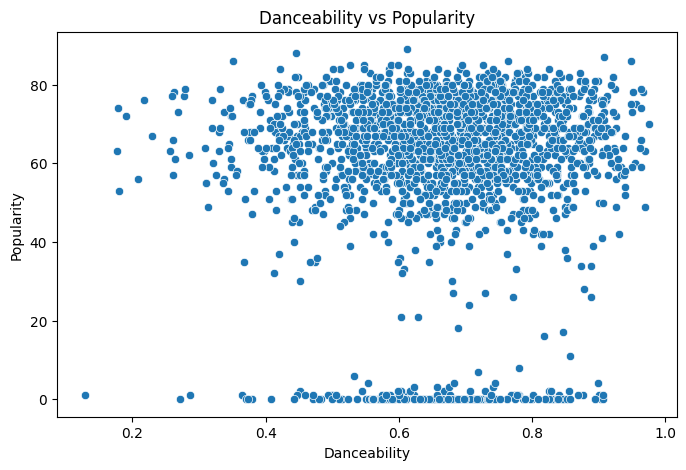

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="danceability",
    y="popularity"
)

plt.title("Danceability vs Popularity")
plt.xlabel("Danceability")
plt.ylabel("Popularity")

plt.show()

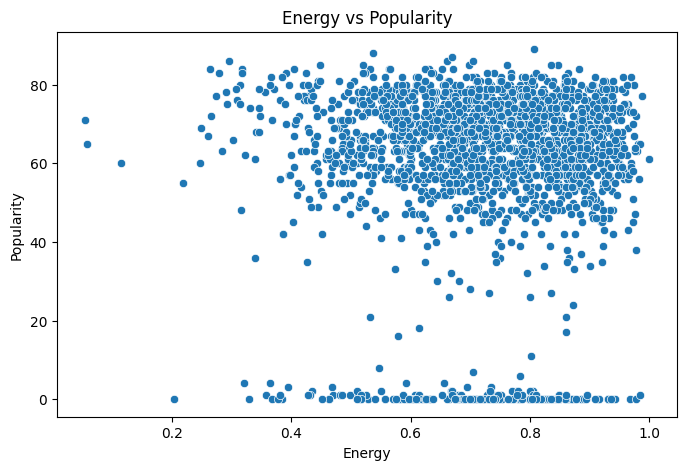

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="energy",
    y="popularity"
)

plt.title("Energy vs Popularity")
plt.xlabel("Energy")
plt.ylabel("Popularity")

plt.show()

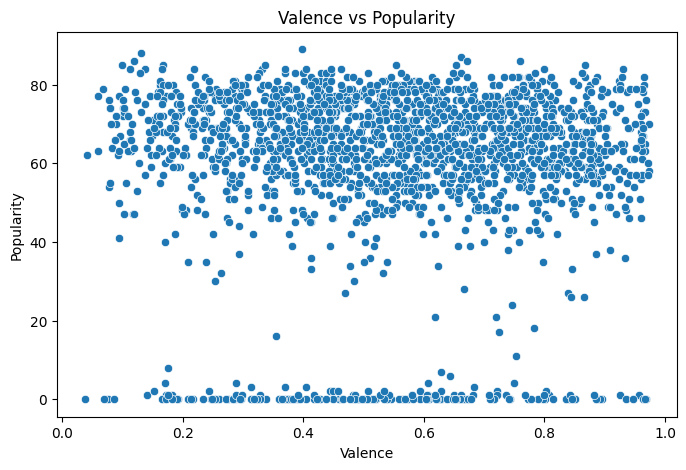

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="valence",
    y="popularity"
)

plt.title("Valence vs Popularity")
plt.xlabel("Valence")
plt.ylabel("Popularity")

plt.show()

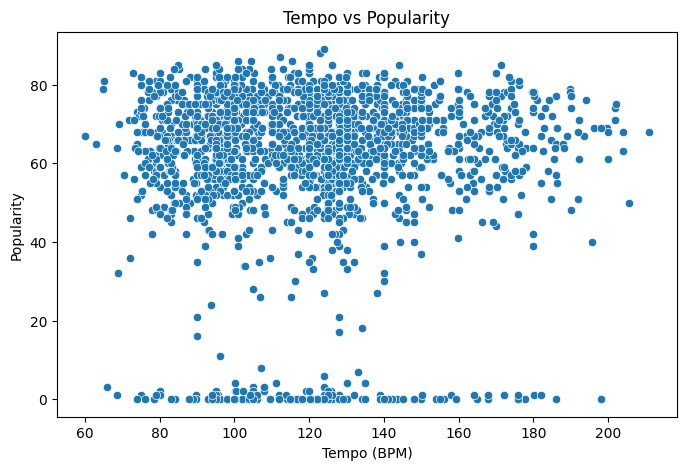

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="tempo",
    y="popularity"
)

plt.title("Tempo vs Popularity")
plt.xlabel("Tempo (BPM)")
plt.ylabel("Popularity")

plt.show()

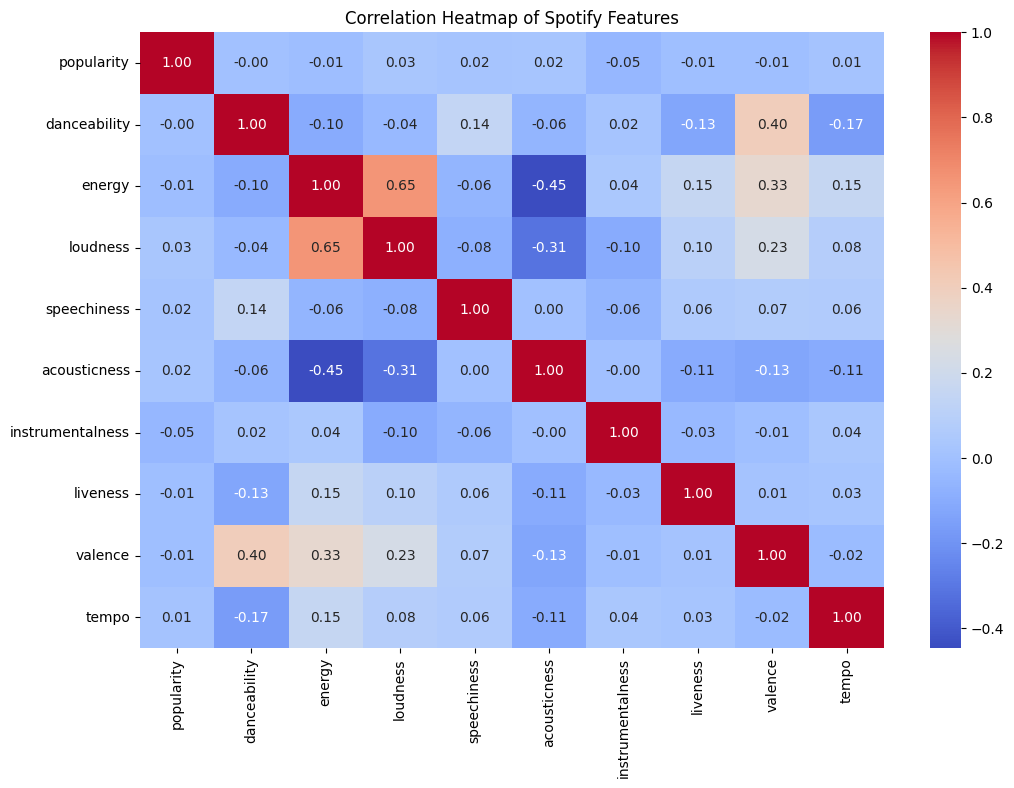

In [ ]:
plt.figure(figsize=(12, 8))

numeric_features = [
    "popularity",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

correlation = df[numeric_features].corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Spotify Features")
plt.show()

In [ ]:

features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

X = df[features]
y = df["popularity_category"]

print("Input features:")
print(features)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Input features:
['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

X shape: (1941, 9)
y shape: (1941,)


In [ ]:
print("X - Input Features")
display(X.head())

X - Input Features


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.751,0.834,-5.444,0.0437,0.3000,0.000018,0.3550,0.894,95.053
1,0.434,0.897,-4.918,0.0488,0.0103,0.000000,0.6120,0.684,148.726
2,0.529,0.496,-9.007,0.0290,0.1730,0.000000,0.2510,0.278,136.859
3,0.551,0.913,-4.063,0.0466,0.0263,0.000013,0.3470,0.544,119.992
4,0.614,0.928,-4.806,0.0516,0.0408,0.001040,0.0845,0.879,172.656


In [ ]:
print("y - Target")
display(y.head())

y - Target


,popularity_category
0,Popular
1,Popular
2,Moderately Popular
3,Popular
4,Moderately Popular


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1552, 9)
Testing data: (389, 9)


In [ ]:
print("Training Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Class Distribution:
popularity_category
Moderately Popular    820
Popular               559
Not Popular           173
Name: count, dtype: int64

Testing Class Distribution:
popularity_category
Moderately Popular    206
Popular               140
Not Popular            43
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [ ]:
print("Scaled training data:")
print(X_train_scaled[:5])

Scaled training data:
[[ 0.8388658  -0.68479094 -0.518761   -0.48084839 -0.72654201 -0.17508349
  -0.94295546  0.85378156 -0.59342732]
 [ 0.59807906 -1.50644427 -0.77206469 -0.34415181  0.96297736 -0.17498407
  -0.62487158 -0.08661265  0.59712156]
 [ 0.88843954 -0.13702205  0.97654784  0.00541577  0.18455763  1.4073223
  -0.76109136 -0.95951444  0.37407415]
 [-0.97411669 -0.79564893 -0.058116   -0.82206809 -0.74635105  4.98683333
  -0.54356762 -0.92801798 -0.88545503]
 [-0.82539547  1.15414747  1.21861628  0.05759004 -0.5706257  -0.17508349
  -0.6512597   1.37572283  1.92078058]]


In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:

y_pred_lr = logistic_model.predict(X_test_scaled)

print("Predictions generated successfully!")
print(y_pred_lr[:20])

Predictions generated successfully!
['Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Popular' 'Moderately Popular'
 'Popular' 'Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular']


In [ ]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", round(lr_accuracy, 4))
print("Logistic Regression Accuracy (%):", round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 0.5141
Logistic Regression Accuracy (%): 51.41 %


In [ ]:
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report")
print("------------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

Logistic Regression Classification Report
------------------------------------------
                    precision    recall  f1-score   support

Moderately Popular       0.54      0.85      0.66       206
       Not Popular       0.00      0.00      0.00        43
           Popular       0.40      0.18      0.25       140

          accuracy                           0.51       389
         macro avg       0.31      0.34      0.30       389
      weighted avg       0.43      0.51      0.44       389



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


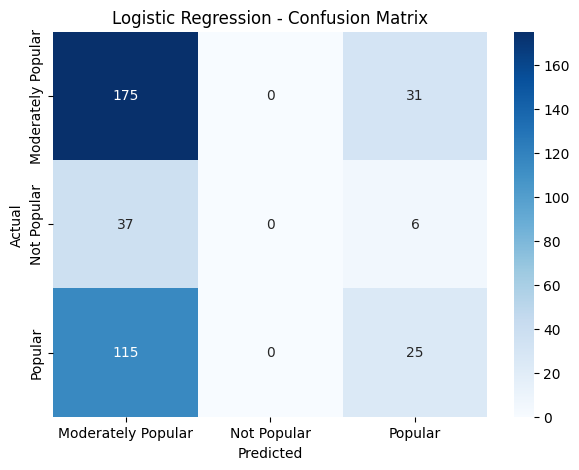

In [ ]:
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=logistic_model.classes_,
    yticklabels=logistic_model.classes_
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

dt_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:

y_pred_dt = dt_model.predict(X_test_scaled)

print("Decision Tree predictions generated successfully!")
print(y_pred_dt[:20])

Decision Tree predictions generated successfully!
['Moderately Popular' 'Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Popular' 'Moderately Popular' 'Moderately Popular'
 'Popular' 'Moderately Popular' 'Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular']


In [ ]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", round(dt_accuracy, 4))
print("Decision Tree Accuracy (%):", round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 0.4936
Decision Tree Accuracy (%): 49.36 %


In [ ]:
from sklearn.metrics import classification_report

print("Decision Tree Classification Report")
print("------------------------------------")

print(classification_report(y_test, y_pred_dt))

Decision Tree Classification Report
------------------------------------
                    precision    recall  f1-score   support

Moderately Popular       0.53      0.79      0.63       206
       Not Popular       0.00      0.00      0.00        43
           Popular       0.37      0.21      0.27       140

          accuracy                           0.49       389
         macro avg       0.30      0.33      0.30       389
      weighted avg       0.41      0.49      0.43       389



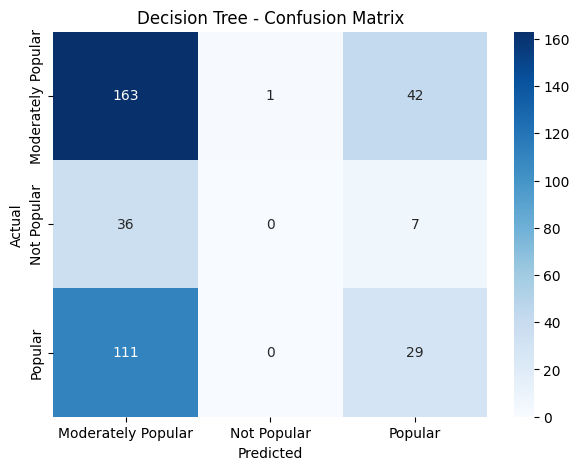

In [ ]:
from sklearn.metrics import confusion_matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:

y_pred_rf = rf_model.predict(X_test_scaled)

print("Random Forest predictions generated successfully!")
print(y_pred_rf[:20])

Random Forest predictions generated successfully!
['Moderately Popular' 'Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Popular' 'Moderately Popular' 'Moderately Popular'
 'Popular' 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular']


In [ ]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(rf_accuracy, 4))
print("Random Forest Accuracy (%):", round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 0.5013
Random Forest Accuracy (%): 50.13 %


In [ ]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report")
print("------------------------------------")

print(classification_report(y_test, y_pred_rf))

Random Forest Classification Report
------------------------------------
                    precision    recall  f1-score   support

Moderately Popular       0.54      0.78      0.64       206
       Not Popular       0.00      0.00      0.00        43
           Popular       0.37      0.24      0.29       140

          accuracy                           0.50       389
         macro avg       0.30      0.34      0.31       389
      weighted avg       0.42      0.50      0.44       389



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


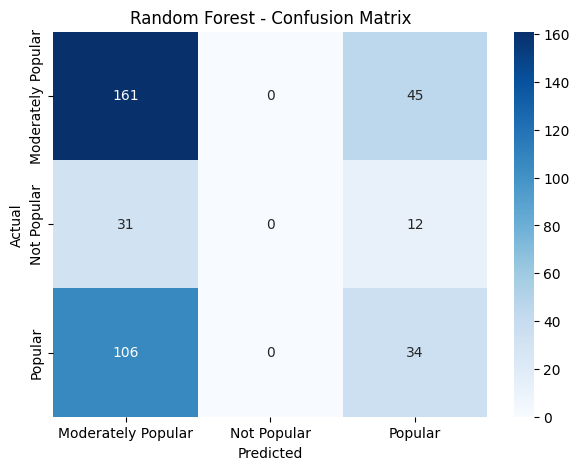

In [ ]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

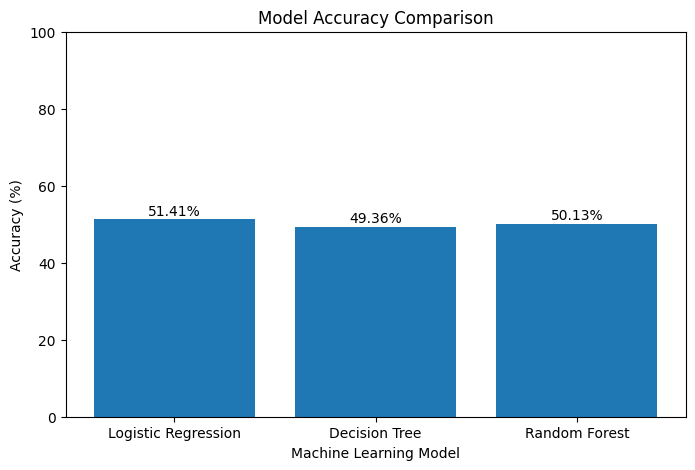

In [ ]:
import matplotlib.pyplot as plt

models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

accuracies = [
    lr_accuracy * 100,
    dt_accuracy * 100,
    rf_accuracy * 100
]

plt.figure(figsize=(8, 5))

plt.bar(models, accuracies)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

Random Forest Feature Importance:
            Feature  Importance
1            energy    0.122152
4      acousticness    0.121315
6          liveness    0.120293
7           valence    0.119927
2          loudness    0.115983
3       speechiness    0.115119
0      danceability    0.112365
8             tempo    0.111868
5  instrumentalness    0.060977


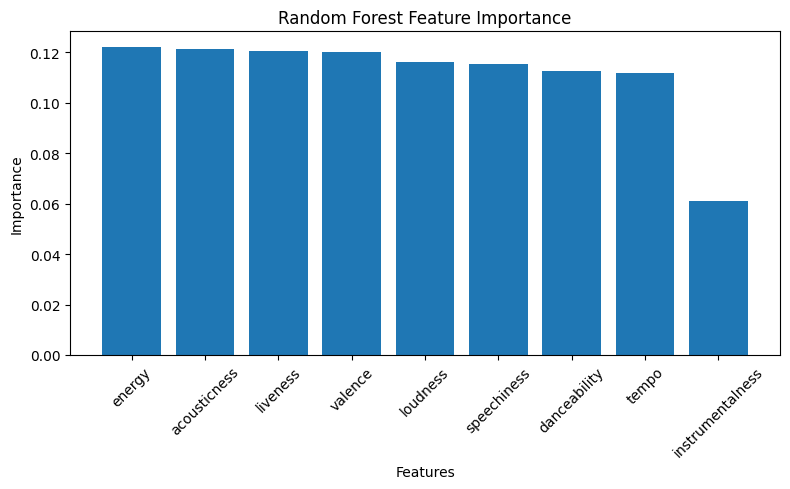

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
print(feature_importance)

plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:

import numpy as np

print("Enter Spotify song features:")

danceability = float(input("Danceability: "))
energy = float(input("Energy: "))
loudness = float(input("Loudness: "))
speechiness = float(input("Speechiness: "))
acousticness = float(input("Acousticness: "))
instrumentalness = float(input("Instrumentalness: "))
liveness = float(input("Liveness: "))
valence = float(input("Valence: "))
tempo = float(input("Tempo: "))

new_song = pd.DataFrame([[
    danceability,
    energy,
    loudness,
    speechiness,
    acousticness,
    instrumentalness,
    liveness,
    valence,
    tempo
]], columns=X.columns)

new_song_scaled = scaler.transform(new_song)

prediction = rf_model.predict(new_song_scaled)

print("\nPredicted Popularity Category:", prediction[0])


Enter Spotify song features:
Danceability: 0.70
Energy: 0.80
Loudness: -5.0
Speechiness: 0.05
Acousticness: 0.10
Instrumentalness: 0.00
Liveness: 0.15
Valence: 0.70
Tempo: 120

Predicted Popularity Category: Popular


In [ ]:
print("========== FINAL PROJECT SUMMARY ==========")

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")
print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

print("\nSample New Song Prediction:", prediction[0])

print("\nProject: Spotify Song Popularity Prediction")
print("Machine Learning Models: Logistic Regression, Decision Tree, Random Forest")

========== FINAL PROJECT SUMMARY ==========
Logistic Regression Accuracy: 51.41 %
Decision Tree Accuracy: 49.36 %
Random Forest Accuracy: 50.13 %

Sample New Song Prediction: Popular

Project: Spotify Song Popularity Prediction
Machine Learning Models: Logistic Regression, Decision Tree, Random Forest
